# The Apprentice Model: demo

Short tour of the project, using the code in `src/`:

1. final results (table, paired tests, figure) from the run files in `results/`
2. the teacher: prompt, parser and one cached answer
3. the two losses on toy numbers
4. a short distillation run (needs `data/` from scripts 02-06, about 2 min on the laptop GPU)
5. teacher vs student on one TREC DL 2019 query

In [1]:
import os, sys, json
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")                      # paths are relative to the repo root
sys.path.insert(0, os.getcwd())
import pandas as pd
from IPython.display import Image, display

## 1. Results
`results/summary.json` comes from `scripts/08_analyze.py`. nDCG@10 is the mean over 3 seeds, "% teacher" is the share of the teacher's nDCG@10, Ovl@10 is the overlap with the teacher's top-10.

In [2]:
S = json.load(open("results/summary.json"))
rows = []
for name, v in S.items():
    if name.startswith("test_"):
        continue
    rows.append({"system": name, "seeds": v["seeds"],
                 "DL19": round(v["dl19"], 3), "DL20": round(v["dl20"], 3),
                 "% teacher": round(50 * (v["ret19"] + v["ret20"]), 1),
                 "val RR@10": round(v["val_rr10"], 3), "Ovl@10": round(v["overlap10"], 2)})
pd.DataFrame(rows).set_index("system")

,seeds,DL19,DL20,% teacher,val RR@10,Ovl@10
system,,,,,,
BM25,1,0.511,0.483,70.7,0.190,0.35
Teacher,1,0.727,0.679,100.0,0.300,1.00
Ref-MiniLM-L6 (500k labels),1,0.740,0.680,101.0,0.391,0.59
tiny-H1,3,0.451,0.366,58.0,0.103,0.27
tiny-H,3,0.470,0.382,60.4,0.120,0.29
tiny-HT,3,0.561,0.491,74.7,0.210,0.39
tiny-T1,3,0.546,0.489,73.5,0.206,0.39
tiny-T,3,0.578,0.504,76.9,0.226,0.41
tiny-Hnat,3,0.549,0.512,75.5,0.238,0.38


In [3]:
tests = [{"test": k[5:].rsplit("_", 1)[0], "size": k.rsplit("_", 1)[1],
          "Δ nDCG@10": round(v["diff"], 3), "p_Holm": round(v["p_holm"], 4)}
         for k, v in S.items() if k.startswith("test_")]
pd.DataFrame(tests).pivot(index="test", columns="size", values=["Δ nDCG@10", "p_Holm"]).reindex(columns=["tiny", "mini", "small"], level=1)

Δ nDCG@10                p_Holm                
size              tiny   mini  small    tiny    mini   small
test                                                        
HT_vs_T         -0.015 -0.012 -0.012  0.0989  0.0989  0.0989
Hnat_vs_H        0.108  0.082  0.087  0.0000  0.0000  0.0000
T_vs_H           0.116  0.099  0.107  0.0000  0.0000  0.0000
T_vs_Hnat        0.008  0.017  0.019  0.4981  0.1860  0.1860
T_vs_Teacher    -0.163 -0.114 -0.076  0.0000  0.0000  0.0001
Tnat_vs_Hnat    -0.011  0.011  0.009  0.7790  0.7790  0.7790

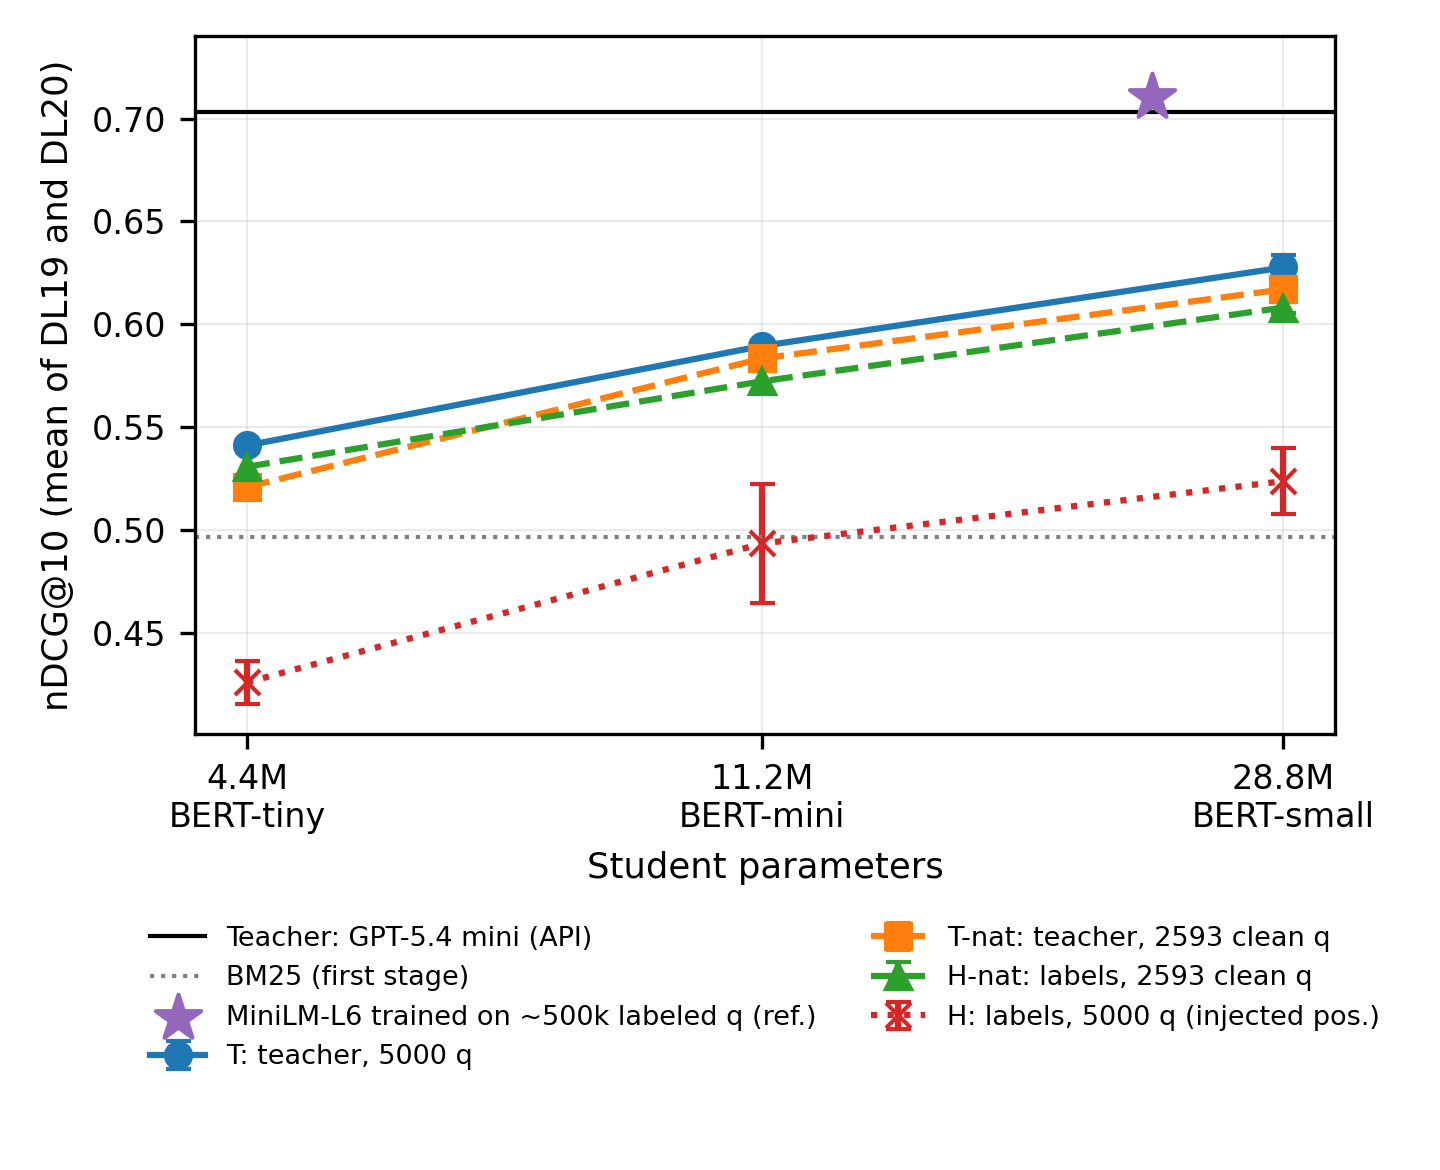

In [4]:
display(Image("results/figures/size_quality.png", width=600))

## 2. The teacher
`build_prompt` numbers the passages and repeats the query at the end. `parse` reads `[i] > [j] > ...`, drops duplicates and adds the ids the model forgot at the end, so the result is always a full permutation.

In [5]:
from src.teacher import build_prompt, parse

query = "how long do cats sleep"
passages = ["Cats are carnivorous mammals of the family Felidae.",
            "Adult cats sleep between 12 and 16 hours a day.",
            "Dogs usually sleep 12 to 14 hours per day."]
print(build_prompt(query, passages))
print(parse("[2] > [3] > [2]", n=3))      # order (0-based), number of missing ids

Below are 3 passages, each marked with an identifier in brackets.
Search query: how long do cats sleep

[1] Cats are carnivorous mammals of the family Felidae.
[2] Adult cats sleep between 12 and 16 hours a day.
[3] Dogs usually sleep 12 to 14 hours per day.

Search query: how long do cats sleep
Rank ALL 3 passages from most to least relevant to the query. Answer only with identifiers in the format [3] > [1] > [2], with no explanation.
([1, 2, 0], 1)


In [6]:
# a real cached answer of GPT-5.4 mini for a training query (30 shuffled candidates)
rec = json.loads(open("cache/teacher/gpt-5.4-mini_train.jsonl").readline())
row = next(json.loads(l) for l in open("data/train_candidates.jsonl") if json.loads(l)["qid"] == rec["qid"])
print("query:", row["query"], "| positive injected:", row["injected"])
print("raw answer:", rec["raw"][:200], "...")
print("labeled positive", row["positives"], "is ranked", rec["ranked_docs"].index(row["positives"][0]) + 1, "by the teacher")

query: what is a bht test | positive injected: False
raw answer: [14] > [17] > [18] > [27] > [23] > [26] > [24] > [20] > [28] > [10] > [19] > [11] > [5] > [22] > [6] > [4] > [7] > [3] > [2] > [1] > [9] > [15] > [25] > [29] > [13] > [8] > [12] > [16] > [21] > [30] ...
labeled positive ['6074953'] is ranked 3 by the teacher


## 3. The two losses
- H, human labels (`infonce_loss`): softmax cross-entropy over the 30 candidates, the labeled passage is the target.
- T, teacher (`ranknet_loss`): RankNet over the 435 pairs ordered by the teacher.

In [7]:
import torch
from src.student import infonce_loss, ranknet_loss

s = torch.tensor([2.0, 1.0, 0.5])         # student scores for 3 passages
print("H, positive = passage 0 (student agrees):", infonce_loss(s, 0).item())
print("H, positive = passage 2 (student disagrees):", infonce_loss(s, 2).item())
print("T, teacher order 0>1>2 (agrees):", ranknet_loss(s, [0, 1, 2]).item())
print("T, teacher order 2>1>0 (reversed):", ranknet_loss(s, [2, 1, 0]).item())

H, positive = passage 0 (student agrees): 0.4643687903881073
H, positive = passage 2 (student disagrees): 1.9643688201904297
T, teacher order 0>1>2 (agrees): 0.3295839726924896
T, teacher order 2>1>0 (reversed): 1.329584002494812


## 4. A short distillation run
BERT-tiny (4.4M), one epoch on the teacher rankings of 500 queries, DL19 score before and after. Needs `data/train_student.json` and `data/eval_dl19.json` (scripts 02-06).

In [8]:
from src.student import CrossEncoder, train_stage, rerank, evaluate

if os.path.exists("data/train_student.json"):
    train = json.load(open("data/train_student.json"))[:500]
    dl19 = json.load(open("data/eval_dl19.json"))
    torch.manual_seed(1)
    ce = CrossEncoder("google/bert_uncased_L-2_H-128_A-2")
    print("BERT-tiny on", ce.device)
    print("DL19 nDCG@10 before training:", round(evaluate(rerank(ce, dl19["data"]), dl19["qrels"], "dl19"), 3))
    train_stage(ce, train, "T", lr=5e-5, seed=11)
    print("DL19 nDCG@10 after 500 teacher-ranked queries:", round(evaluate(rerank(ce, dl19["data"]), dl19["qrels"], "dl19"), 3))
else:
    print("data/ not found: run scripts 01, 02, 06 first")

W1115 11:15:15.148000 32451 .venv/lib/python3.11/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/bert_uncased_L-2_H-128_A-2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT-tiny on mps
DL19 nDCG@10 before training: 0.255
DL19 nDCG@10 after 500 teacher-ranked queries: 0.493


## 5. Teacher vs student on one DL19 query
Top-5 of the teacher and of BERT-small trained on the teacher (seed 1), same 100 BM25 candidates, with the NIST grade (0-3) of each passage.

In [9]:
qrels = json.load(open("results/qrels.json"))["dl19"]
teacher = json.load(open("results/runs/teacher_dl19.json"))
student = json.load(open("results/runs/student_small_T_s1_dl19.json"))
texts = json.load(open("data/eval_dl19.json"))["data"] if os.path.exists("data/eval_dl19.json") else None

qid = sorted(teacher)[0]
def top(run, k=5):
    return sorted(run[qid], key=run[qid].get, reverse=True)[:k]
for name, run in [("teacher", teacher), ("student small-T", student)]:
    print(f"--- {name}")
    for d in top(run):
        snippet = texts[qid]["docs"][d][:90] if texts else ""
        print(f"  {d:>8}  rel={qrels[qid].get(d, '-')}  {snippet}")
if texts:
    print("query:", texts[qid]["query"])

--- teacher
   8760866  rel=0  Robert Gray was the Democratic candidate for governor of Mississippi in the 2015 elections
   8760871  rel=3  Atlantic Ocean, United States. Robert Gray, (born May 10, 1755, Tiverton, R.I.—died summer
   3620983  rel=0  I'm not a politician, said Gray in a Wednesday interview. I'm not a person who really want
   8760870  rel=0  Source: Courtney Ann Jackson/Twitter. JACKSON, MS (Mississippi News Now) -. A surprise cam
   8760867  rel=0  Robert Gray. A surprise came on the Democratic side in the race for Mississippi Governor. 
--- student small-T
   8760871  rel=3  Atlantic Ocean, United States. Robert Gray, (born May 10, 1755, Tiverton, R.I.—died summer
   8760867  rel=0  Robert Gray. A surprise came on the Democratic side in the race for Mississippi Governor. 
   2157450  rel=0  Robert Gray Army Air Field Airport is located approximately 9,1 kilometers (5,6 miles) sou
   8760866  rel=0  Robert Gray was the Democratic candidate for governor of Mississippi 